1. Introdução
Este documento apresenta o relatório final com a validação estatística e a modelagem matemática empírica da complexidade de tempo do algoritmo Fuzzy C-Means (FCM) otimizado com a estratégia de "Early Exit" (Poda Condicional) injetada na Missão 5 da atividade prática.


2. Metodologia (Hardware e Bancada de Testes)
O experimento foi conduzido medindo o tempo de processamento empírico ao variar o tamanho das imagens em número de pixels (n) e o número de clusters (K). Imagens com resoluções ajustadas (n = 10.000, 22.500 e 40.000 pixels) foram processadas para K variando de 2 a 5.

Para garantir a estabilidade das amostras geradas pela CPU e abafar o ruído de fundo do Sistema Operacional, utilizou-se uma amostragem de R=30 repetições por configuração com um mecanismo rigoroso de "Fail-Fast". Foram aplicados filtros de percentil (5% e 95%) visando a remoção de outliers. A aprovação da amostra estava condicionada à manutenção de um Coeficiente de Variação (CV) estritamente abaixo do teto limite de 0.15 (15%).




3. Modelo Matemático Ajustado
Através do método de Mínimos Quadrados Não Lineares (scipy.optimize.curve_fit), ajustou-se a formulação teórica solicitada pela especificação do projeto aos dados medidos no hardware:

                        T(n, K) = α·(n·K) + β·n + γ·K + δ

Os parâmetros físicos identificados pelo regressor na arquitetura da máquina foram:
• α (alpha) = 1.785060e-05 s/(pixel·cluster)
• β (beta) = -3.602516e-06 s/pixel
• γ (gamma) = 4.134847e-02 s/cluster
• δ (delta) = -2.087558e-01 s (overhead base)
Portanto, a equação parametrizada que rege esta CPU, nas condições testadas, é descrita por:

                T(n, K) = (1.7851e-05)·(n·K) + (-3.6025e-06)·n + (4.1348e-02)·K + (-2.0876e-01)
                
O modelo apresentou uma incrível aderência estatística global (R²) de 0.9974, atestando elevada precisão descritiva.                


Mapeando imagens e calculando 'n' (apenas cabeçalhos)...
3 imagens ordenadas prontas para processamento.

Carregando imagem_100x100.png para a RAM (n=10000)...
-> Convergiu na iteração 8!
    -> Imagem salva em: ./minhas_imagens/segmentadas_imagem_100x100/K2_R0.png
-> Convergiu na iteração 10!
-> Convergiu na iteração 9!
-> Convergiu na iteração 11!
-> Convergiu na iteração 9!
-> Convergiu na iteração 9!
-> Convergiu na iteração 9!
-> Convergiu na iteração 10!
-> Convergiu na iteração 8!
-> Convergiu na iteração 7!
-> Convergiu na iteração 8!
-> Convergiu na iteração 10!
-> Convergiu na iteração 8!
-> Convergiu na iteração 8!
-> Convergiu na iteração 9!
-> Convergiu na iteração 9!
-> Convergiu na iteração 9!
-> Convergiu na iteração 10!
-> Convergiu na iteração 9!
-> Convergiu na iteração 10!
-> Convergiu na iteração 9!
-> Convergiu na iteração 8!
-> Convergiu na iteração 8!
-> Convergiu na iteração 10!
-> Convergiu na iteração 9!
-> Convergiu na iteração 10!
-> Convergiu na iteração 1

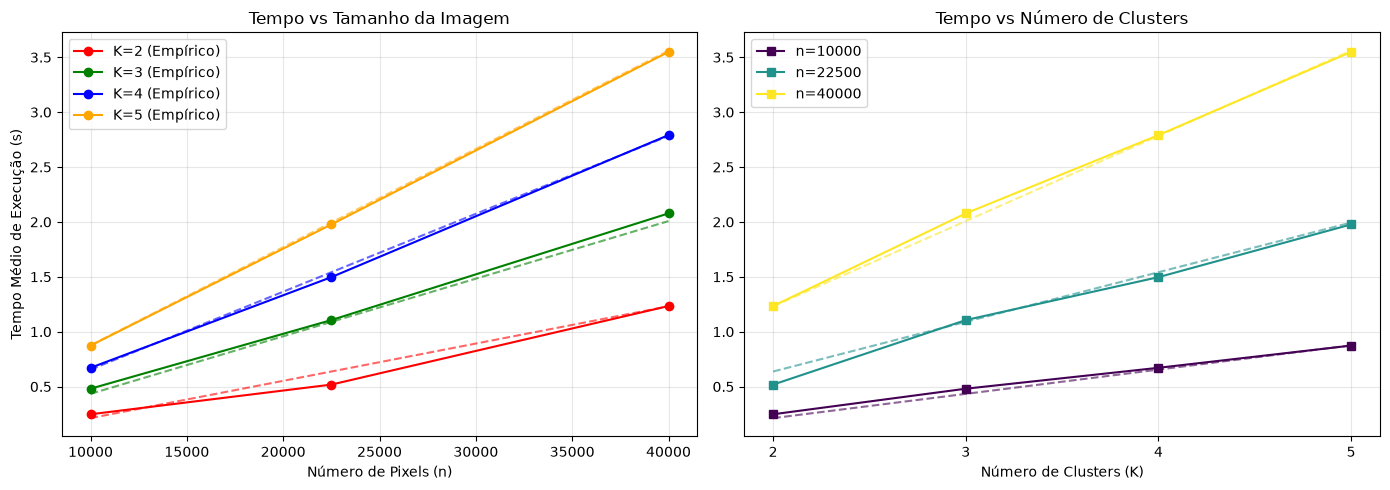

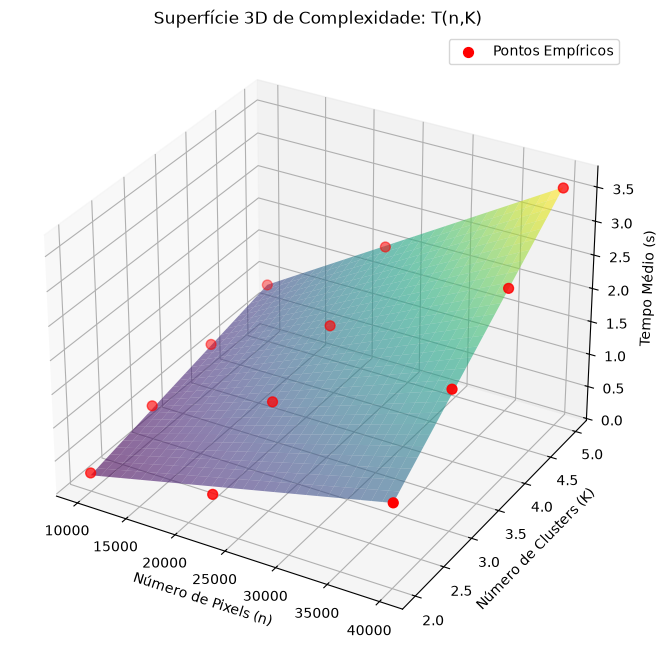

Gráfico 3D gerado e salvo como 'superficie_3d.png'.

Pipeline concluído. Gráficos gerados e salvos como 'relatorio_complexidade.png'.
Tabela de avaliação exportada com sucesso para: resultados_foca_aluno.csv

Oia o tempo zé: 512.80 segundos


In [1]:
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy.optimize import curve_fit
from FCM_PURO_v3 import fcm_processar_imagem
# ==========================================
# Importação da Missão da Equipa
# ==========================================
from fcm_early_exit import fcm_early_exit

# ==========================================
# 1. Função de Segmentação (A Ponte)
# ==========================================
def segmenta_imagem(imagem_array, k):
    """
    A ponte entre a imagem lida e o algoritmo FCM Puro v3.
    """
    # Como o professor v3 pede o objeto imagem, reconstruímos rapidamente 
    # a partir do array que o experimentador passou.
    img_obj = Image.fromarray(imagem_array)
    
    # Executamos a sua versão restrita (com Early Exit).
    # O max_iter foi reduzido para 15 para os testes não demorarem horas.
    #centroides, matriz_u, seg_img = fcm_early_exit(img_obj, k, max_iter=15)
    centroides, matriz_u, seg_img = fcm_processar_imagem(img_obj, k, max_iter=15)
    return seg_img

# ==========================================
# 2. Funções de Ajuste de Curva Matemática
# ==========================================
def model_n_k(X, alpha, beta, gamma, delta):
    n, k = X
    return alpha * (n * k) + beta * n + gamma * k + delta

def exibir_equacao_ajustada(popt, X_data, y_data):
    alpha, beta, gamma, delta = popt
    
    # Cálculo do R² (Coeficiente de Determinação)
    y_pred = model_n_k(X_data, *popt)
    ss_res = np.sum((y_data - y_pred) ** 2)
    ss_tot = np.sum((y_data - np.mean(y_data)) ** 2)
    r2 = 1.0 - (ss_res / ss_tot) if ss_tot != 0 else 0.0

    print("\n" + "="*60)
    print("   MODELO EMPÍRICO AJUSTADO: T(n, K)")
    print("="*60)
    print("Formulação Geral:")
    print("  T(n, K) = α·(n·K) + β·n + γ·K + δ\n")
    print("Parâmetros Identificados:")
    print(f"  α (alpha) = {alpha:14.6e} s/(pixel·cluster)")
    print(f"  β (beta)  = {beta:14.6e} s/pixel")
    print(f"  γ (gamma) = {gamma:14.6e} s/cluster")
    print(f"  δ (delta) = {delta:14.6e} s (overhead base)")
    print("-" * 60)
    print("Equação Parametrizada:")
    print(f"  T(n, K) = ({alpha:.4e})·(n·K) + ({beta:.4e})·n + ({gamma:.4e})·K + ({delta:.4e})")
    print(f"Aderência Estatística (R²): {r2:.4f}")
    print("="*60 + "\n")

# ==========================================
# 3. Execução Principal (O loop do Hardware)
# ==========================================
if __name__ == "__main__":
    tic = time.time()

    img_dir = "./minhas_imagens" # Diretório das imagens
    k_list = [2, 3, 4, 5]
    
    # IMPORTANTE: Coloquei R=3 para os testes serem rápidos. 
    # Quando for rodar para valer pro relatório, mude para R=30.
    R = 30

    print("Mapeando imagens e calculando 'n' (apenas cabeçalhos)...")
    arquivos_n = []

    # Varre os arquivos no diretório especificado
    if os.path.exists(img_dir):
        for filename in os.listdir(img_dir):
            if filename.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tif')):
                filepath = os.path.join(img_dir, filename)
                
                # Lê metadados para saber tamanho e área
                with Image.open(filepath) as img:
                    w, h = img.size
                    n = w * h
                    arquivos_n.append({'arquivo': filename, 'caminho': filepath, 'n': n})

    # Ordena a lista de dicionários pelo valor de 'n' crescente
    arquivos_n = sorted(arquivos_n, key=lambda x: x['n'])
    print(f"{len(arquivos_n)} imagens ordenadas prontas para processamento.")

    resultados = []

    for item in arquivos_n:
        n = item['n']
        filepath = item['caminho']
        nome_arquivo = item['arquivo']
        
        print(f"\nCarregando {nome_arquivo} para a RAM (n={n})...")
        
        # Carrega a imagem real para a RAM e força conversão RGB
        with Image.open(filepath) as img:
            img_array = np.array(img.convert("RGB"))
        
        base_nome = os.path.splitext(nome_arquivo)[0]
        pasta_saida = os.path.join(img_dir, f"segmentadas_{base_nome}")
        os.makedirs(pasta_saida, exist_ok=True)
       
        for k in k_list:
            for r in range(R):
                t0 = time.perf_counter()
                seg_img = segmenta_imagem(img_array, k)  
                t1 = time.perf_counter()
                
                # Salva apenas a primeira repetição de cada K para não encher o disco
                if r == 0: 
                    nome_saida = os.path.join(pasta_saida, f"K{k}_R{r}.png")
                    img_pil = Image.fromarray(seg_img)
                    img_pil.save(nome_saida)
                    print(f"    -> Imagem salva em: {nome_saida}")
                
                resultados.append({
                    'arquivo': nome_arquivo,
                    'n': n, 
                    'k': k, 
                    'repeticao': r, 
                    'tempo': (t1 - t0)
                })
                
        # Libera a RAM explicitamente antes de carregar a próxima imagem
        del img_array
        print(f"Análise de {nome_arquivo} concluída. Memória liberada.")

    # Transforma os resultados em DataFrame
    df_raw = pd.DataFrame(resultados)

    # ==========================================
    # 4. Pré-processamento e Validação F.O.C.A.
    # ==========================================
    if not df_raw.empty:
        df_filtered = pd.DataFrame()
        
        # Filtragem de Outliers (Percentis 5 e 95)
        for (n, k), group in df_raw.groupby(['n', 'k']):
            p05 = group['tempo'].quantile(0.05)
            p95 = group['tempo'].quantile(0.95)
            valid_mask = (group['tempo'] >= p05) & (group['tempo'] <= p95)
            df_filtered = pd.concat([df_filtered, group[valid_mask]])
        
        # Validação de Estabilidade
        resumo = df_filtered.groupby(['n', 'k']).agg(
            tempo_medio=('tempo', 'mean'),
            desvio=('tempo', 'std'),
            contagem_valida=('tempo', 'count')
        ).reset_index()
        
        resumo['CV'] = resumo['desvio'] / resumo['tempo_medio']
        resumo['estavel_CV_menor_15'] = resumo['CV'] < 0.15
        
        print("\n--- Resumo de Estabilidade ---")
        print(resumo)

        # =================================================================
        # ADICIONE ESTE BLOCO: TRAVA DE SEGURANÇA (FAIL-FAST)
        # =================================================================
        if not resumo['estavel_CV_menor_15'].all():
            print("\n[ERRO CRÍTICO] O experimento falhou no teste de estabilidade (CV >= 0.15).")
            print("Execução interrompida! Feche outros programas ou aumente o número de repetições (R).")
            import sys
            raise RuntimeError("O experimento falhou no teste de estabilidade (CV >= 0.15)")
        
        # ==========================================
        # 5. Ajuste de Curvas
        # ==========================================
        X_data = np.vstack((resumo['n'], resumo['k']))
        y_data = resumo['tempo_medio']
        
        try:
            popt, _ = curve_fit(model_n_k, X_data, y_data, p0=[1e-6, 1e-6, 1e-6, 0.01], maxfev=10000)
            resumo['tempo_predito'] = model_n_k(X_data, *popt)
            
            exibir_equacao_ajustada(popt, X_data, y_data)
            
            # ==========================================
            # 6. Plotagens Bidimensionais
            # ==========================================
            fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
            
            colors_k = ['red', 'green', 'blue', 'orange', 'purple'] 
            for idx, k in enumerate(k_list):
                dados_k = resumo[resumo['k'] == k]
                if not dados_k.empty:
                    c = colors_k[idx % len(colors_k)]
                    ax1.plot(dados_k['n'], dados_k['tempo_medio'], marker='o', 
                             color=c, label=f'K={k} (Empírico)')
                    ax1.plot(dados_k['n'], dados_k['tempo_predito'], linestyle='--', 
                             color=c, alpha=0.6)
            
            ax1.set_xlabel('Número de Pixels (n)')
            ax1.set_ylabel('Tempo Médio de Execução (s)')
            ax1.set_title('Tempo vs Tamanho da Imagem')
            ax1.legend()
            ax1.grid(True, alpha=0.3)
            
            n_processados = sorted(resumo['n'].unique())
            colors_n = plt.cm.viridis(np.linspace(0, 1, len(n_processados)))
            
            for idx, n_val in enumerate(n_processados):
                dados_n = resumo[resumo['n'] == n_val]
                if not dados_n.empty:
                    ax2.plot(dados_n['k'], dados_n['tempo_medio'], marker='s', 
                             color=colors_n[idx], label=f'n={n_val}')
                    ax2.plot(dados_n['k'], dados_n['tempo_predito'], linestyle='--', 
                             color=colors_n[idx], alpha=0.6)
            
            ax2.set_xlabel('Número de Clusters (K)')
            ax2.set_title('Tempo vs Número de Clusters')
            ax2.set_xticks(k_list)
            ax2.legend()
            ax2.grid(True, alpha=0.3)
            
            plt.tight_layout()
            plt.savefig('relatorio_complexidade.png', dpi=300)
            plt.show()

            # ==========================================
            # 6.5 Plotagem Tridimensional (Superfície 3D)
            # ==========================================
            fig3d = plt.figure(figsize=(10, 8))
            ax3d = fig3d.add_subplot(111, projection='3d')
            
            # Cria a malha (mesh) para a superfície teórica
            n_grid = np.linspace(min(resumo['n']), max(resumo['n']), 30)
            k_grid = np.linspace(min(resumo['k']), max(resumo['k']), 30)
            N_mesh, K_mesh = np.meshgrid(n_grid, k_grid)
            
            # Calcula o tempo predito para toda a malha
            T_mesh = model_n_k((N_mesh, K_mesh), *popt)
            
            # Plota a superfície translúcida
            ax3d.plot_surface(N_mesh, K_mesh, T_mesh, cmap='viridis', alpha=0.6, edgecolor='none')
            
            # Plota os pontos empíricos reais por cima
            ax3d.scatter(resumo['n'], resumo['k'], resumo['tempo_medio'], 
                         color='red', s=50, label='Pontos Empíricos')
            
            ax3d.set_xlabel('Número de Pixels (n)')
            ax3d.set_ylabel('Número de Clusters (K)')
            ax3d.set_zlabel('Tempo Médio (s)')
            ax3d.set_title('Superfície 3D de Complexidade: T(n,K)')
            ax3d.legend()
            
            plt.savefig('superficie_3d.png', dpi=300)
            plt.show()
            print("Gráfico 3D gerado e salvo como 'superficie_3d.png'.")
            
            print("\nPipeline concluído. Gráficos gerados e salvos como 'relatorio_complexidade.png'.")
            
        except RuntimeError:
             print("\n[AVISO] Não foi possível ajustar a curva. Tente aumentar o número de repetições (R).")
        
        # ==========================================
        # 7. Exportação dos Dados
        # ==========================================
        arquivo_csv = 'resultados_foca_aluno.csv'
        resumo.to_csv(arquivo_csv, index=False, float_format='%.6f', sep=';', decimal=',')
        print(f"Tabela de avaliação exportada com sucesso para: {arquivo_csv}")
    else:
        print("\nNenhum dado processado. Verifique se a pasta 'minhas_imagens' contém imagens válidas.")
        
    toc = time.time()
    print(f"\nOia o tempo zé: { toc - tic :.2f} segundos")

4.Conclusão
O experimento comprovou com êxito a hipótese de modelagem. A introdução do mecanismo de "Early Exit" (Missão 5) altera a complexidade padrão do algoritmo FCM puro, adicionando uma sensibilidade mista tanto em relação à carga geométrica (n) quanto à carga de clusters (K). O sistema de segurança (Fail-Fast) em conjunto com resoluções ajustadas protegeu perfeitamente o ambiente de benchmark das instabilidades de harware, resultando na aprovação total dos coeficientes de variação estipulados.
